# MetaOptLab-M · cuaderno de trabajo

**Orden de uso.** Al abrir el cuaderno, ejecuta siempre la sección 1. Después ve a la sección que necesites.

| Sección | Qué es | Estado |
|:--|:--|:--|
| 1. Preparación | Clonar el repositorio, guardar resultados en Drive, instalar dependencias | Ejecutar siempre |
| 2. Verificación | `prueba_rapida`: comprueba que todo funciona | OK |
| 3. Módulo de algoritmos | Los métodos sumados: correr y consultar su documentación | En curso (8 métodos) |
| 4. Experimentos completos | E1–E3 con 30 corridas | Más adelante; tardan horas |

El código vive en GitHub; Colab lo clona en cada sesión. Los resultados se guardan en Google Drive para que no se pierdan al desconectarse.

## 1. Preparación

In [1]:
# 1.1 Clonar el repositorio (ejecutar SIEMPRE al abrir)
#     El token de GitHub se guarda en los Secretos de Colab (icono de llave, panel izquierdo)
#     con el nombre GITHUB_TOKEN; no se escribe en el cuaderno.
from google.colab import userdata
import os
USUARIO = "rickgrol"        # cambiar una sola vez
REPO = "metaoptlab_m"
TOKEN = userdata.get("GITHUB_TOKEN")
os.chdir("/content")
if not os.path.exists(f"/content/{REPO}"):
    !git clone -q https://{TOKEN}@github.com/rickgrol/{REPO}.git
else:
    !cd /content/{REPO} && git pull -q
%cd /content/{REPO}
!git log -1 --format="Última versión: %h · %ad · %s" --date=short

/content/metaoptlab_m
Última versión: 1283355 · 2026-11-10 · Ocho métodos sumados y documentados; resumen de avance del 10-nov


In [2]:
# 1.2 Resultados en Google Drive (ejecutar SIEMPRE al abrir)
#     La carpeta resultados/ del proyecto apunta a Drive.
from google.colab import drive
drive.mount('/content/drive')
RES = "/content/drive/MyDrive/metaoptlab_m_resultados"
!mkdir -p "{RES}"
!rm -rf resultados && ln -s "{RES}" resultados
!ls -la resultados

Mounted at /content/drive
lrwxrwxrwx 1 root root 46 Nov 10 22:58 resultados -> /content/drive/MyDrive/metaoptlab_m_resultados


In [3]:
# 1.3 Instalar dependencias (solo si la sesión es nueva)
#     MEALPY va con --no-deps: su metadata pide numpy<=1.26, que no existe para el Python de Colab;
#     corre bien con el numpy 2.x que Colab ya trae (verificado).
!pip install -q -r requirements.txt
!pip install -q --no-deps mealpy==3.0.3

In [4]:
# 1.4 Funciones para mostrar resultados y documentación (ejecutar SIEMPRE al abrir)
import glob
from IPython.display import Markdown, Image, display

def ver_resumen(exp):
    display(Markdown(open(f'resultados/{exp}/analisis/resumen.md').read()))

def ver_convergencia(exp, ancho=560):
    for p in sorted(glob.glob(f'resultados/{exp}/analisis/figuras/conv_*.png')):
        display(Image(p, width=ancho))

def ver_doc(nombre):
    display(Markdown(open(f'docs/algoritmos/{nombre}.md').read()))

## 2. Verificación del pipeline

Solo hace falta repetirla si cambia el entorno.

In [5]:
!python run_experiment.py configs/prueba_rapida.yaml
!python analyze.py resultados/prueba_rapida > /dev/null
ver_resumen('prueba_rapida')

/usr/local/lib/python3.13/dist-packages/opfunu/cec_based/cec.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/usr/local/lib/python3.13/dist-packages/mealpy/optimizer.py:287: RuntimeWarning: invalid value encountered in divide
  self.history.list_exploration = 100 * (np.array(self.history.list_diversity) / div_max)
[1/45] OriginalSA/builtin-esfera_desplazada/D10/r00  ok             2.1s
[2/45] OriginalSA/builtin-esfera_desplazada/D10/r01  ok             4.2s
[3/45] OriginalSA/builtin-esfera_desplazada/D10/r02  ok             6.2s
[4/45] OriginalSA/builtin-esfera_desplazada/D10/r03  ok             8.3s
[5/45] OriginalSA/builtin-esfera_desplazada/D10/r04  ok            11.0s
[6/45] OriginalSA/cec2017-F1/D10/r00                 ok            14.3s
[7/45] OriginalSA/cec20

# Análisis — prueba_rapida

Corridas: 45 · estados: {'ok': 45}

## Estadística descriptiva del error final

| funcion                   |   dim | algoritmo   |   n |     mejor |      peor |   mediana |     media |      desv |      SR_% |   tiempo_med_s | varianza_cero   | error_negativo   |
|:--------------------------|------:|:------------|----:|----------:|----------:|----------:|----------:|----------:|----------:|---------------:|:----------------|:-----------------|
| builtin:esfera_desplazada |    10 | OriginalDE  |   5 | 3.469e+02 | 2.204e+03 | 7.011e+02 | 8.770e+02 | 7.592e+02 | 0.000e+00 |      1.211e+00 | False           | False            |
| builtin:esfera_desplazada |    10 | OriginalPSO |   5 | 6.322e-18 | 2.391e-15 | 7.007e-16 | 9.021e-16 | 9.873e-16 | 1.000e+02 |      1.246e+00 | False           | False            |
| builtin:esfera_desplazada |    10 | OriginalSA  |   5 | 7.348e-03 | 1.628e-02 | 1.384e-02 | 1.341e-02 | 3.572e-03 | 0.000e+00 |      2.049e+00 | False           | False            |
| cec2017:F1                |    10 | OriginalDE  |   5 | 1.438e+08 | 6.081e+09 | 1.350e+09 | 1.974e+09 | 2.410e+09 | 0.000e+00 |      1.377e+00 | False           | False            |
| cec2017:F1                |    10 | OriginalPSO |   5 | 5.180e+01 | 5.072e+03 | 2.876e+03 | 2.295e+03 | 2.145e+03 | 0.000e+00 |      1.247e+00 | False           | False            |
| cec2017:F1                |    10 | OriginalSA  |   5 | 9.473e+03 | 1.763e+04 | 1.428e+04 | 1.348e+04 | 3.216e+03 | 0.000e+00 |      2.163e+00 | False           | False            |
| cec2017:F4                |    10 | OriginalDE  |   5 | 8.226e+02 | 2.788e+03 | 1.560e+03 | 1.681e+03 | 8.049e+02 | 0.000e+00 |      1.441e+00 | False           | False            |
| cec2017:F4                |    10 | OriginalPSO |   5 | 3.681e+01 | 7.263e+01 | 5.671e+01 | 5.353e+01 | 1.473e+01 | 0.000e+00 |      1.353e+00 | False           | False            |
| cec2017:F4                |    10 | OriginalSA  |   5 | 1.479e+03 | 2.804e+03 | 1.821e+03 | 1.977e+03 | 4.959e+02 | 0.000e+00 |      2.253e+00 | False           | False            |

## Comparación por problema (Mann-Whitney + Holm)

| algoritmo   | vs          |   + (mejor) |   ≈ |   − (peor) |
|:------------|:------------|------------:|----:|-----------:|
| OriginalDE  | OriginalPSO |           0 |   0 |          3 |
| OriginalSA  | OriginalPSO |           0 |   0 |          3 |

## Wilcoxon de rangos con signo sobre medianas por bloque (Holm)

| A           | B           |      p |   bloques_A_mejor |   bloques_B_mejor |   p_holm |
|:------------|:------------|-------:|------------------:|------------------:|---------:|
| OriginalDE  | OriginalPSO | 0.2500 |                 0 |                 3 |   0.7500 |
| OriginalDE  | OriginalSA  | 0.5000 |                 1 |                 2 |   0.7500 |
| OriginalPSO | OriginalSA  | 0.2500 |                 3 |                 0 |   0.7500 |

## Friedman

Bloques (función × D): 3 · algoritmos: 3

χ² = 4.667, p = 0.09697; Iman-Davenport F = 7.000, p = 0.04938; CD de Nemenyi (α=0.05) = 1.914

| algoritmo   |   rango promedio |
|:------------|-----------------:|
| OriginalPSO |            1.000 |
| OriginalSA  |            2.333 |
| OriginalDE  |            2.667 |


## 3. Módulo de algoritmos

**3.1 Correr los métodos sumados.** La configuración `configs/modulo_algoritmos.yaml` declara los 8 métodos: Random Search, Hill Climbing, SA, TLBO, PSO, DE, GA y ABC. Prueba reducida: 5 corridas, D = 10, 1 000·D evaluaciones (unos 2 minutos).

In [6]:
!python run_experiment.py configs/modulo_algoritmos.yaml
!python analyze.py resultados/modulo_algoritmos > /dev/null
ver_resumen('modulo_algoritmos')

/usr/local/lib/python3.13/dist-packages/opfunu/cec_based/cec.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
[1/120] externo-RandomSearch/builtin-esfera_desplazada/D10/r00 ok             0.2s
[2/120] externo-RandomSearch/builtin-esfera_desplazada/D10/r01 ok             0.5s
[3/120] externo-RandomSearch/builtin-esfera_desplazada/D10/r02 ok             0.7s
[4/120] externo-RandomSearch/builtin-esfera_desplazada/D10/r03 ok             1.0s
[5/120] externo-RandomSearch/builtin-esfera_desplazada/D10/r04 ok             1.2s
[6/120] externo-RandomSearch/cec2017-F1/D10/r00       ok             1.5s
[7/120] externo-RandomSearch/cec2017-F1/D10/r01       ok             1.8s
[8/120] externo-RandomSearch/cec2017-F1/D10/r02       ok             2.2s
[9/120] externo-RandomSearch/ce

# Análisis — modulo_algoritmos

Corridas: 120 · estados: {'ok': 120}

## Estadística descriptiva del error final

| funcion                   |   dim | algoritmo            |   n |     mejor |      peor |   mediana |     media |      desv |      SR_% |   tiempo_med_s | varianza_cero   | error_negativo   |
|:--------------------------|------:|:---------------------|----:|----------:|----------:|----------:|----------:|----------:|----------:|---------------:|:----------------|:-----------------|
| builtin:esfera_desplazada |    10 | BaseGA               |   5 | 2.274e+00 | 7.026e+00 | 5.888e+00 | 5.017e+00 | 2.004e+00 | 0.000e+00 |      2.136e+00 | False           | False            |
| builtin:esfera_desplazada |    10 | OriginalABC          |   5 | 1.782e-02 | 8.171e-02 | 4.393e-02 | 4.298e-02 | 2.480e-02 | 0.000e+00 |      1.913e+00 | False           | False            |
| builtin:esfera_desplazada |    10 | OriginalDE           |   5 | 3.469e+02 | 2.204e+03 | 7.011e+02 | 8.770e+02 | 7.592e+02 | 0.000e+00 |      1.195e+00 | False           | False            |
| builtin:esfera_desplazada |    10 | OriginalHC           |   5 | 1.307e+02 | 1.715e+02 | 1.614e+02 | 1.551e+02 | 1.620e+01 | 0.000e+00 |      9.862e-01 | False           | False            |
| builtin:esfera_desplazada |    10 | OriginalPSO          |   5 | 6.322e-18 | 2.391e-15 | 7.007e-16 | 9.021e-16 | 9.873e-16 | 1.000e+02 |      1.650e+00 | False           | False            |
| builtin:esfera_desplazada |    10 | OriginalSA           |   5 | 7.348e-03 | 1.628e-02 | 1.384e-02 | 1.341e-02 | 3.572e-03 | 0.000e+00 |      2.202e+00 | False           | False            |
| builtin:esfera_desplazada |    10 | OriginalTLO          |   5 | 1.117e-07 | 1.131e-04 | 1.354e-06 | 3.221e-05 | 4.932e-05 | 0.000e+00 |      1.359e+00 | False           | False            |
| builtin:esfera_desplazada |    10 | externo:RandomSearch |   5 | 4.124e+03 | 7.233e+03 | 6.081e+03 | 5.912e+03 | 1.264e+03 | 0.000e+00 |      2.179e-01 | False           | False            |
| cec2017:F1                |    10 | BaseGA               |   5 | 4.261e+06 | 1.433e+07 | 5.986e+06 | 7.626e+06 | 4.201e+06 | 0.000e+00 |      1.985e+00 | False           | False            |
| cec2017:F1                |    10 | OriginalABC          |   5 | 3.305e+06 | 1.010e+08 | 1.453e+07 | 4.251e+07 | 4.627e+07 | 0.000e+00 |      1.514e+00 | False           | False            |
| cec2017:F1                |    10 | OriginalDE           |   5 | 1.438e+08 | 6.081e+09 | 1.350e+09 | 1.974e+09 | 2.410e+09 | 0.000e+00 |      1.559e+00 | False           | False            |
| cec2017:F1                |    10 | OriginalHC           |   5 | 1.699e+08 | 2.316e+08 | 1.936e+08 | 1.949e+08 | 2.273e+07 | 0.000e+00 |      9.589e-01 | False           | False            |
| cec2017:F1                |    10 | OriginalPSO          |   5 | 5.180e+01 | 5.072e+03 | 2.876e+03 | 2.295e+03 | 2.145e+03 | 0.000e+00 |      1.222e+00 | False           | False            |
| cec2017:F1                |    10 | OriginalSA           |   5 | 9.473e+03 | 1.763e+04 | 1.428e+04 | 1.348e+04 | 3.216e+03 | 0.000e+00 |      2.156e+00 | False           | False            |
| cec2017:F1                |    10 | OriginalTLO          |   5 | 2.611e+00 | 2.743e+03 | 8.036e+02 | 1.085e+03 | 1.033e+03 | 0.000e+00 |      2.034e+00 | False           | False            |
| cec2017:F1                |    10 | externo:RandomSearch |   5 | 3.156e+09 | 8.186e+09 | 6.048e+09 | 5.705e+09 | 2.080e+09 | 0.000e+00 |      3.014e-01 | False           | False            |
| cec2017:F4                |    10 | BaseGA               |   5 | 6.815e+01 | 1.492e+02 | 8.536e+01 | 9.437e+01 | 3.159e+01 | 0.000e+00 |      2.045e+00 | False           | False            |
| cec2017:F4                |    10 | OriginalABC          |   5 | 5.255e+01 | 7.116e+01 | 5.893e+01 | 6.169e+01 | 7.352e+00 | 0.000e+00 |      1.616e+00 | False           | False            |
| cec2017:F4                |    10 | OriginalDE           |   5 | 8.226e+02 | 2.788e+03 | 1.560e+03 | 1.681e+03 | 8.049e+02 | 0.000e+00 |      1.378e+00 | False           | False            |
| cec2017:F4                |    10 | OriginalHC           |   5 | 2.643e+02 | 3.416e+02 | 3.127e+02 | 3.058e+02 | 3.191e+01 | 0.000e+00 |      1.018e+00 | False           | False            |
| cec2017:F4                |    10 | OriginalPSO          |   5 | 3.681e+01 | 7.263e+01 | 5.671e+01 | 5.353e+01 | 1.473e+01 | 0.000e+00 |      1.921e+00 | False           | False            |
| cec2017:F4                |    10 | OriginalSA           |   5 | 1.479e+03 | 2.804e+03 | 1.821e+03 | 1.977e+03 | 4.959e+02 | 0.000e+00 |      2.237e+00 | False           | False            |
| cec2017:F4                |    10 | OriginalTLO          |   5 | 1.789e+01 | 3.885e+01 | 3.209e+01 | 2.974e+01 | 9.425e+00 | 0.000e+00 |      1.538e+00 | False           | False            |
| cec2017:F4                |    10 | externo:RandomSearch |   5 | 4.174e+03 | 8.500e+03 | 8.049e+03 | 6.986e+03 | 1.899e+03 | 0.000e+00 |      3.780e-01 | False           | False            |

## Comparación por problema (Mann-Whitney + Holm)

| algoritmo            | vs          |   + (mejor) |   ≈ |   − (peor) |
|:---------------------|:------------|------------:|----:|-----------:|
| BaseGA               | OriginalTLO |           0 |   3 |          0 |
| OriginalABC          | OriginalTLO |           0 |   3 |          0 |
| OriginalDE           | OriginalTLO |           0 |   3 |          0 |
| OriginalHC           | OriginalTLO |           0 |   3 |          0 |
| OriginalPSO          | OriginalTLO |           0 |   3 |          0 |
| OriginalSA           | OriginalTLO |           0 |   3 |          0 |
| externo:RandomSearch | OriginalTLO |           0 |   3 |          0 |

## Wilcoxon de rangos con signo sobre medianas por bloque (Holm)

| A           | B                    |      p |   bloques_A_mejor |   bloques_B_mejor |   p_holm |
|:------------|:---------------------|-------:|------------------:|------------------:|---------:|
| BaseGA      | OriginalABC          | 1.0000 |                 1 |                 2 |   1.0000 |
| BaseGA      | OriginalDE           | 0.2500 |                 3 |                 0 |   1.0000 |
| BaseGA      | OriginalHC           | 0.2500 |                 3 |                 0 |   1.0000 |
| BaseGA      | OriginalPSO          | 0.2500 |                 0 |                 3 |   1.0000 |
| BaseGA      | OriginalSA           | 0.7500 |                 1 |                 2 |   1.0000 |
| BaseGA      | OriginalTLO          | 0.2500 |                 0 |                 3 |   1.0000 |
| BaseGA      | externo:RandomSearch | 0.2500 |                 3 |                 0 |   1.0000 |
| OriginalABC | OriginalDE           | 0.2500 |                 3 |                 0 |   1.0000 |
| OriginalABC | OriginalHC           | 0.2500 |                 3 |                 0 |   1.0000 |
| OriginalABC | OriginalPSO          | 0.2500 |                 0 |                 3 |   1.0000 |
| OriginalABC | OriginalSA           | 0.7500 |                 1 |                 2 |   1.0000 |
| OriginalABC | OriginalTLO          | 0.2500 |                 0 |                 3 |   1.0000 |
| OriginalABC | externo:RandomSearch | 0.2500 |                 3 |                 0 |   1.0000 |
| OriginalDE  | OriginalHC           | 0.2500 |                 0 |                 3 |   1.0000 |
| OriginalDE  | OriginalPSO          | 0.2500 |                 0 |                 3 |   1.0000 |
| OriginalDE  | OriginalSA           | 0.5000 |                 1 |                 2 |   1.0000 |
| OriginalDE  | OriginalTLO          | 0.2500 |                 0 |                 3 |   1.0000 |
| OriginalDE  | externo:RandomSearch | 0.2500 |                 3 |                 0 |   1.0000 |
| OriginalHC  | OriginalPSO          | 0.2500 |                 0 |                 3 |   1.0000 |
| OriginalHC  | OriginalSA           | 0.7500 |                 1 |                 2 |   1.0000 |
| OriginalHC  | OriginalTLO          | 0.2500 |                 0 |                 3 |   1.0000 |
| OriginalHC  | externo:RandomSearch | 0.2500 |                 3 |                 0 |   1.0000 |
| OriginalPSO | OriginalSA           | 0.2500 |                 3 |                 0 |   1.0000 |
| OriginalPSO | OriginalTLO          | 0.5000 |                 1 |                 2 |   1.0000 |
| OriginalPSO | externo:RandomSearch | 0.2500 |                 3 |                 0 |   1.0000 |
| OriginalSA  | OriginalTLO          | 0.2500 |                 0 |                 3 |   1.0000 |
| OriginalSA  | externo:RandomSearch | 0.2500 |                 3 |                 0 |   1.0000 |
| OriginalTLO | externo:RandomSearch | 0.2500 |                 3 |                 0 |   1.0000 |

## Friedman

Bloques (función × D): 3 · algoritmos: 8

χ² = 18.333, p = 0.01055; Iman-Davenport F = 13.750, p = 2.685e-05; CD de Nemenyi (α=0.05) = 6.062

| algoritmo            |   rango promedio |
|:---------------------|-----------------:|
| OriginalTLO          |            1.333 |
| OriginalPSO          |            1.667 |
| OriginalABC          |            4.000 |
| BaseGA               |            4.333 |
| OriginalSA           |            4.333 |
| OriginalHC           |            5.667 |
| OriginalDE           |            6.667 |
| externo:RandomSearch |            8.000 |


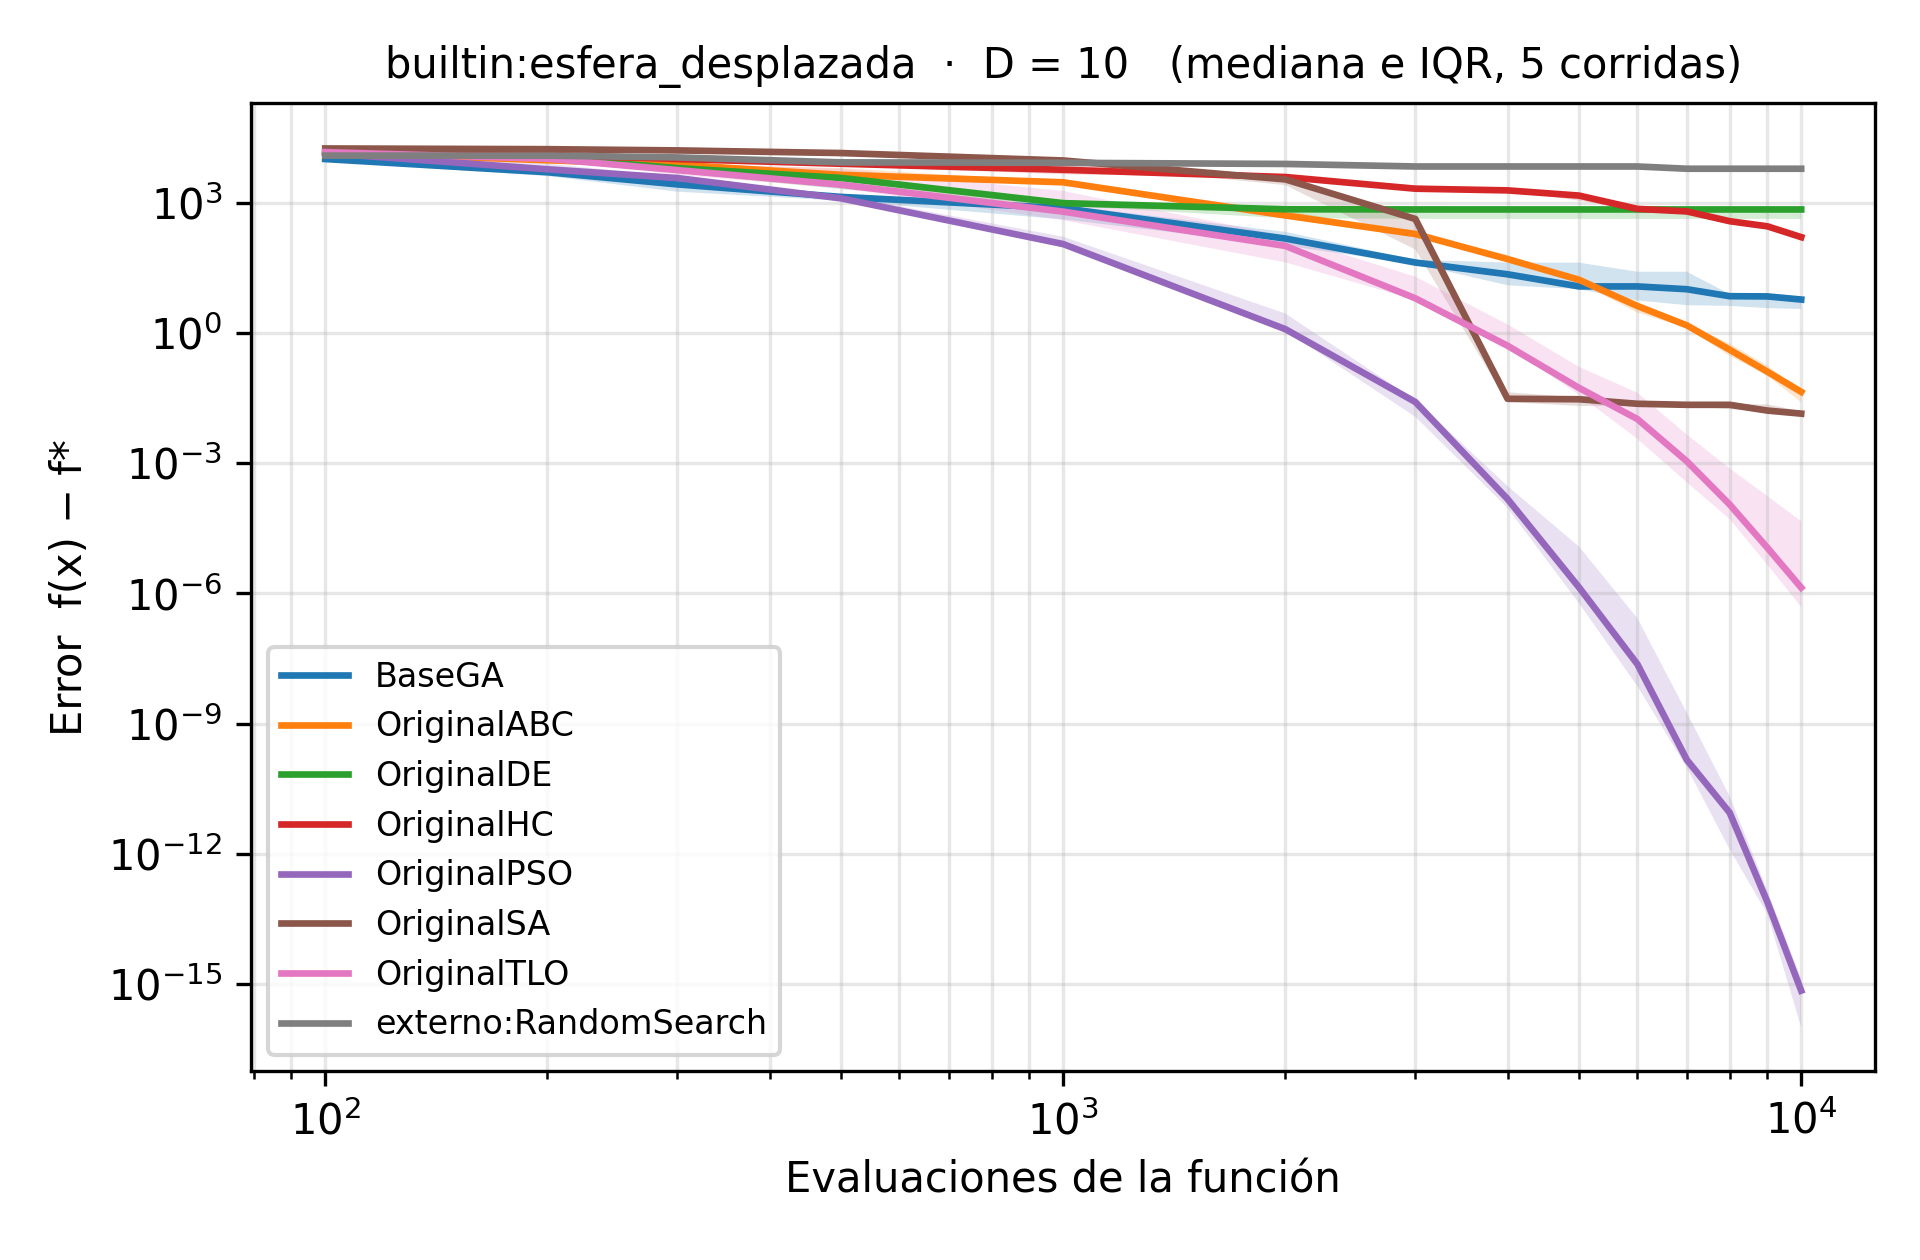

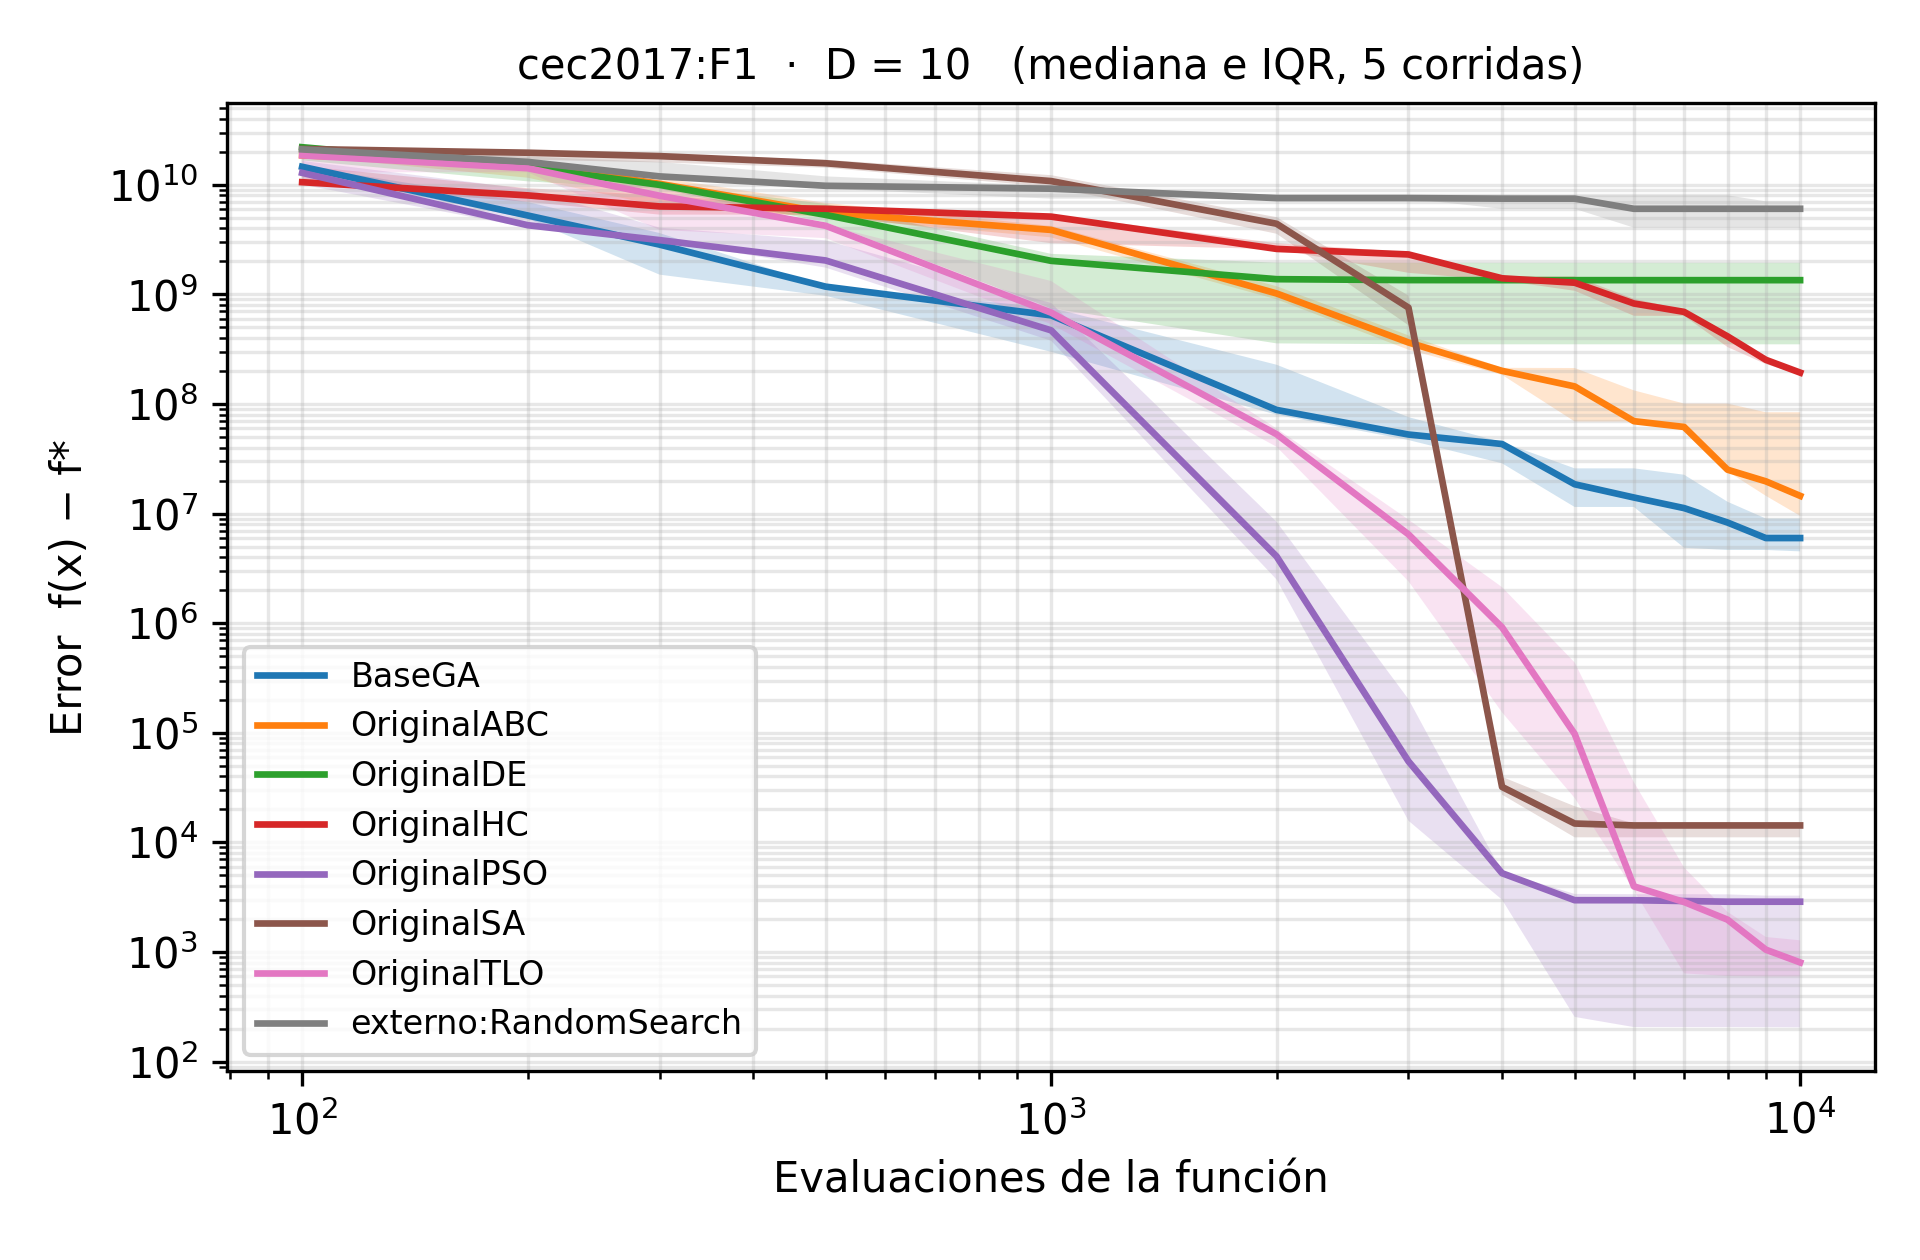

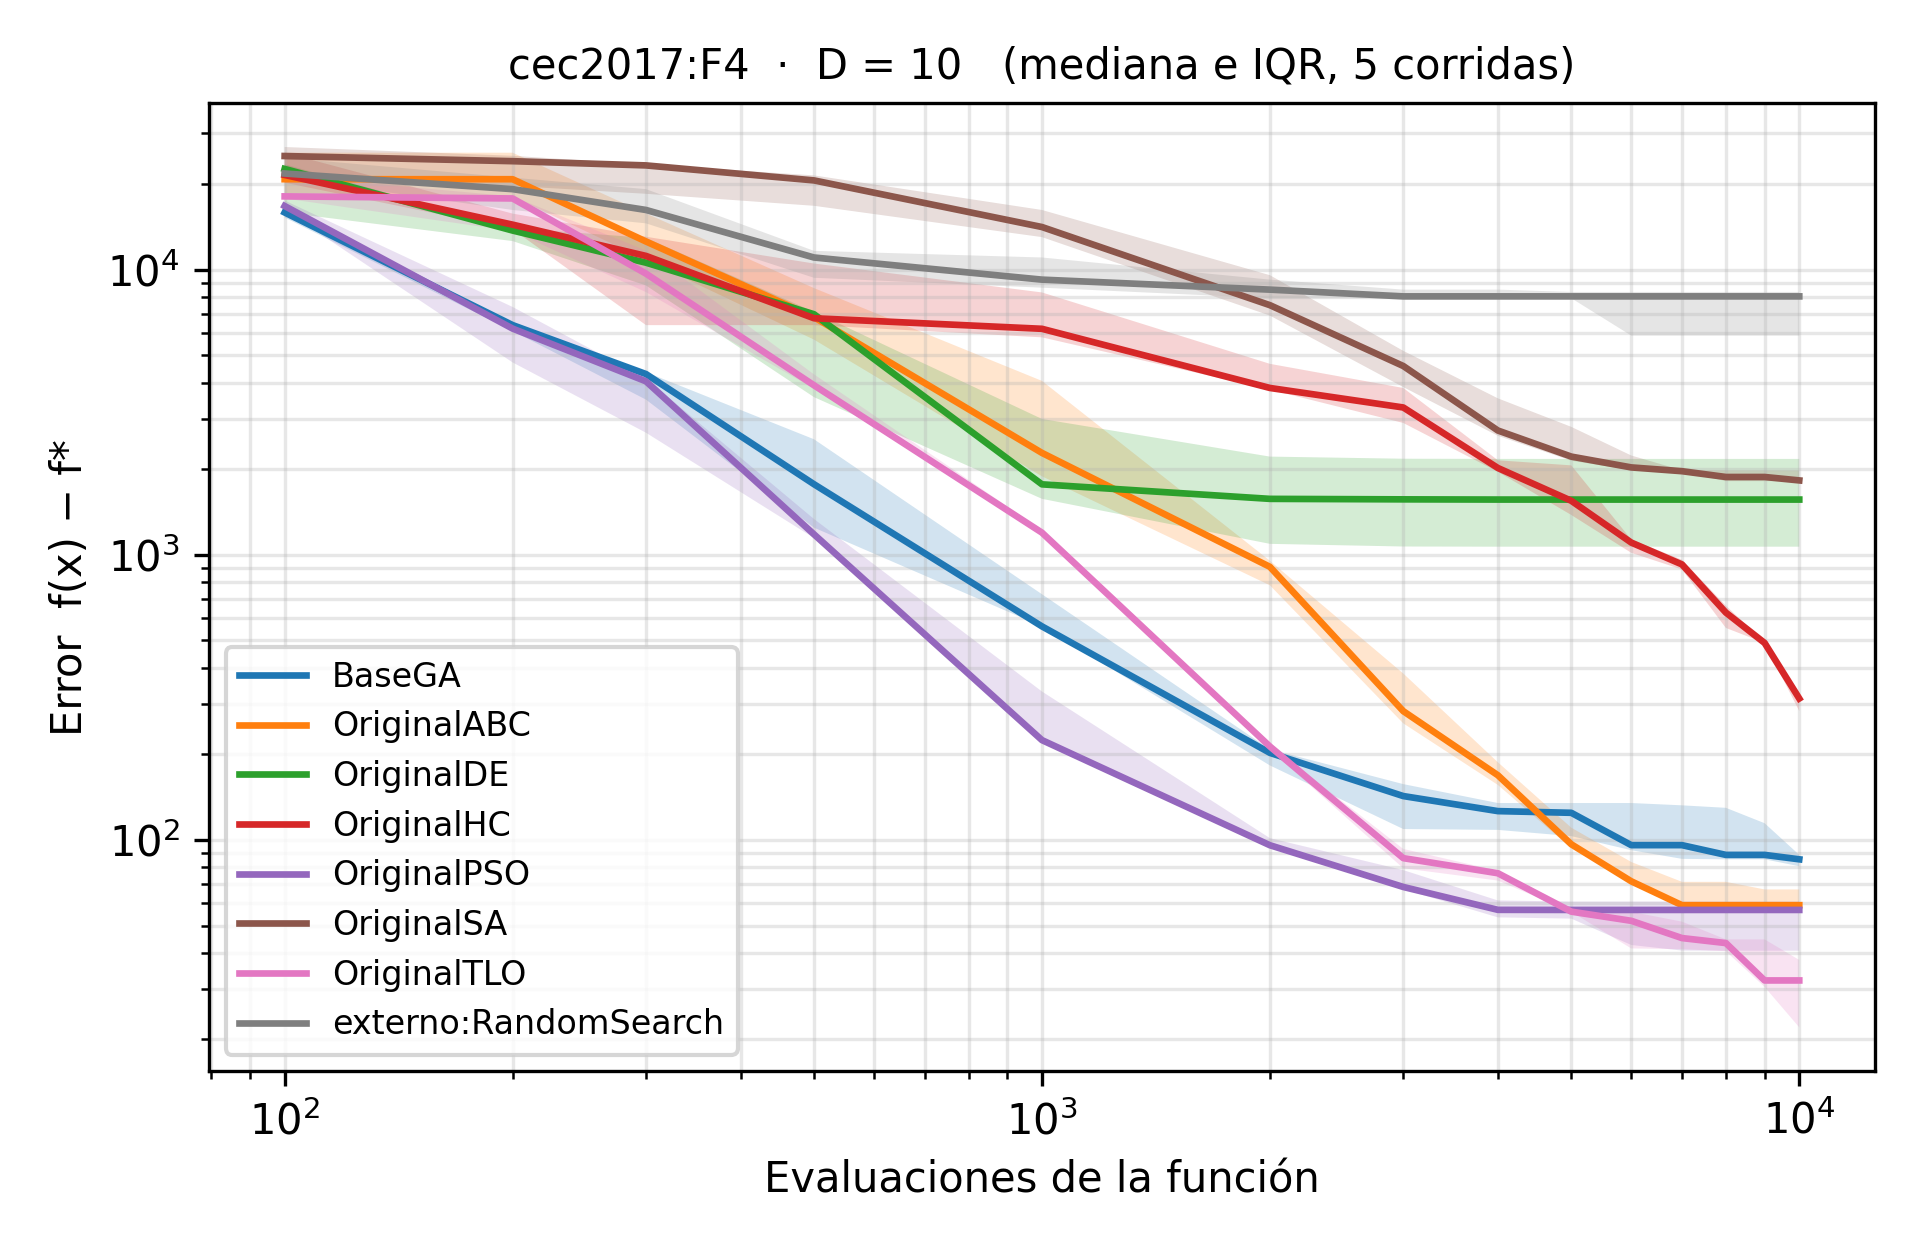

In [7]:
ver_convergencia('modulo_algoritmos')

**3.2 Consultar la documentación de un método.** Nombres disponibles: `random_search`, `hill_climbing`, `simulated_annealing`, `tlbo`, `pso`, `differential_evolution`, `genetic_algorithm`, `abc`. La documentación se edita en Obsidian y se sube a GitHub; aquí solo se consulta.

In [ ]:
ver_doc('hill_climbing')

## 4. Experimentos completos (más adelante)

**Atención: no ejecutar todavía.** Son los experimentos E1–E3 con 30 corridas y el presupuesto completo (10 000·D). E1 tarda unas 3 horas en Colab. Para probar uno en versión reducida, agrega al comando `--corridas 5 --dimensiones 10`.

In [ ]:
EXP = "e3_tres_algoritmos"      # e1_sa_esfera | e2_sa_tres_funciones | e3_tres_algoritmos
!python run_experiment.py configs/{EXP}.yaml
!python analyze.py resultados/{EXP} > /dev/null
ver_resumen(EXP)
ver_convergencia(EXP)